# Module 13 Assignment: Web Data & APIs
**CS 5045: Computation for the Data Sciences**

**Name:** Vaishnavi Madagiri

---

This assignment uses the Open-Meteo API to retrieve a real 7-day weather forecast for a city of your choice. Open-Meteo is free and requires no account or API key.

**Important:** Run **Section 1** once with internet access. It saves the response to `weather_response.json` in this folder. All other sections load from that saved file, so you can complete the rest of the assignment offline.

**Submit:** commit and push `hw13.ipynb` to your fork on GitHub; no Canvas upload needed. Run all cells top to bottom before submitting. No errors should appear.

**Also needed for Section 7:** the local C compiler you set up for Seminar 3.

In [6]:
import json
import requests
import pandas as pd
import matplotlib.pyplot as plt

## Section 1: Fetch the Data

**Run this section once with internet access.** It makes one API call and saves the response to `weather_response.json`.

The Open-Meteo URL pattern is:
```
https://api.open-meteo.com/v1/forecast
  ?latitude=LAT
  &longitude=LON
  &daily=temperature_2m_max,temperature_2m_min,precipitation_sum
  &timezone=TIMEZONE
```

Look up your city's latitude and longitude at https://www.latlong.net or use the examples below:

| City | Latitude | Longitude | Timezone |
|------|----------|-----------|----------|
| Blacksburg, VA | 37.2296 | -80.4139 | America/New_York |
| Chicago, IL | 41.8781 | -87.6298 | America/Chicago |
| Los Angeles, CA | 34.0522 | -118.2437 | America/Los_Angeles |
| London, UK | 51.5074 | -0.1278 | Europe/London |
| Tokyo, Japan | 35.6762 | 139.6503 | Asia/Tokyo |

In [7]:
# Fill in the latitude, longitude, and timezone for your chosen city.
# Replace the blanks below with real values from the table or latlong.net.

MY_CITY     = 'Blacksburg, VA'   # example: 'Blacksburg, VA'
MY_LAT      = 37.2296     # example: 37.2296
MY_LON      = -80.4139     # example: -80.4139
MY_TIMEZONE = 'America/New_York'   # example: 'America/New_York'

URL = 'https://api.open-meteo.com/v1/forecast'
params = {
    'latitude':  MY_LAT,
    'longitude': MY_LON,
    'daily': 'temperature_2m_max,temperature_2m_min,precipitation_sum',
    'timezone': MY_TIMEZONE,
}

response = requests.get(URL, params=params)

# Always check the status code before using the response.
if response.status_code == 200:
    data = response.json()
    print('Success! Status:', response.status_code)
else:
    print('Error:', response.status_code)
    raise SystemExit('Fix the URL parameters and try again.')

# Save the response so the rest of the notebook works offline.
with open('weather_response.json', 'w') as f:
    json.dump(data, f, indent=2)

print('Saved: weather_response.json')
print('Top-level keys:', list(data.keys()))

Success! Status: 200
Saved: weather_response.json
Top-level keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']


---
## Section 2: Parse the JSON

Load the saved response and navigate the JSON structure to extract the daily data.

The Open-Meteo response has this shape:
```json
{
  "latitude": ...,
  "longitude": ...,
  "daily": {
    "time":               ["2026-09-01", "2026-09-02", ...],
    "temperature_2m_max": [28.4, 27.1, ...],
    "temperature_2m_min": [17.2, 16.4, ...],
    "precipitation_sum":  [0.0, 1.2, ...]
  }
}
```

Note: `data["daily"]` is a **dict of parallel lists**, not a list of dicts.

In [4]:
# Load from the saved file.
# Sections 2-5 use this cell, not a live API call.
with open('weather_response.json') as f:
    data = json.load(f)

print('Loaded weather_response.json')

Loaded weather_response.json


In [8]:
# 2a. Print the top-level keys of the response.
#     Expected: something like ['latitude', 'longitude', 'timezone', 'daily', ...]
print('Top-level keys:', list(data.keys()))

# 2b. Print the keys inside data["daily"].
#     Expected: ['time', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum']
daily = data['daily']
print('Daily keys:', list(daily.keys()))

# 2c. Print the list of dates (the 'time' key inside daily).
#     Expected: a list of 7 date strings like ['2026-09-01', '2026-09-02', ...]
print('Dates:', daily['time'])

# 2d. Print the list of daily maximum temperatures.
#     Expected: a list of 7 floats
print('Max temps (C):', daily['temperature_2m_max'])

# 2e. Print just the maximum temperature for the FIRST day.
#     Hint: index into the list you just printed.
print('Max temp day 1 (C):', daily['temperature_2m_max'][0])

Top-level keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']
Daily keys: ['time', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum']
Dates: ['2026-11-22', '2026-11-23', '2026-11-24', '2026-11-25', '2026-11-26', '2026-11-27', '2026-11-28']
Max temps (C): [14.0, 14.7, 8.7, 5.4, 6.0, 4.5, 10.3]
Max temp day 1 (C): 14.0


---
## Section 3: Build the DataFrame

`pd.DataFrame()` can accept a dict of parallel lists directly. Each key becomes a column name; each list becomes the column's values. The result is a DataFrame with one row per day.

In [9]:
# 3a. Build a DataFrame from data["daily"].
#     Fill in the blank: pd.DataFrame takes the dict of parallel lists.
df = pd.DataFrame(data['daily'])

# 3b. Print the shape.
#     Expected: (7, 4), meaning 7 days and 4 columns
print('Shape:', df.shape)

# 3c. Print the first 5 rows.
print('\nFirst 5 rows:')
print(df.head())

Shape: (7, 4)

First 5 rows:
         time  temperature_2m_max  temperature_2m_min  precipitation_sum
0  2026-11-22                14.0                10.2                0.0
1  2026-11-23                14.7                 1.4                0.0
2  2026-11-24                 8.7                -3.4                0.0
3  2026-11-25                 5.4                -4.4                0.0
4  2026-11-26                 6.0                 3.2               50.0


---
## Section 4: Visualize

Create a line plot showing both the daily maximum temperature and daily minimum temperature over the 7-day period. Add a title, x-label, and y-label. Use the 'time' column for the x-axis.

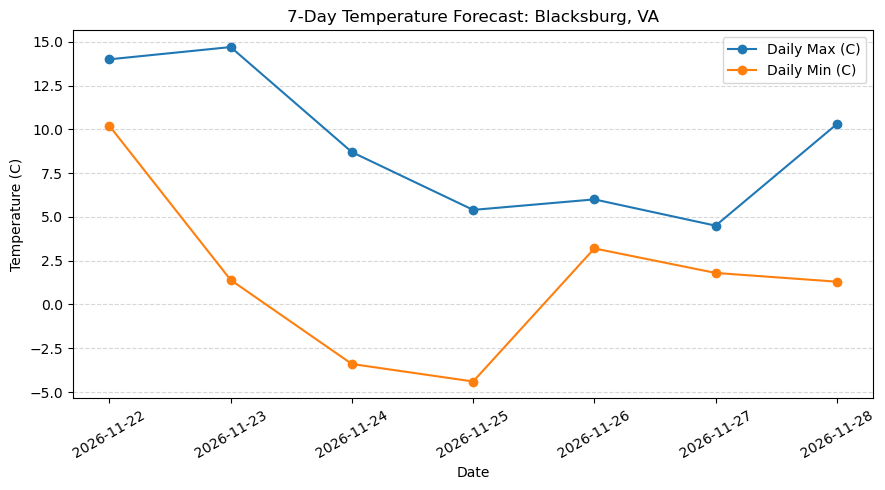

In [10]:
# 4a. Create a line plot with two lines: max temp and min temp.
#     Use plt.plot() for each line, or df.plot() if you prefer pandas plotting.
#     Fill in the blanks below.

fig, ax = plt.subplots(figsize=(9, 5))

# Line 1: daily maximum temperature
ax.plot(df['time'], df['temperature_2m_max'],
        marker='o', label='Daily Max (C)')

# Line 2: daily minimum temperature
ax.plot(df['time'], df['temperature_2m_min'],
        marker='o', label='Daily Min (C)')

# 4b. Fill in the title and axis labels.
ax.set_title('7-Day Temperature Forecast: Blacksburg, VA')
ax.set_xlabel('Date')
ax.set_ylabel('Temperature (C)')

ax.tick_params(axis='x', rotation=30)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## Section 5: Interpret

Answer these two questions in the markdown cells below. Write in plain English (no code required).

**5a. Temperature range.** What is the approximate range between the daily maximum and minimum temperatures for your chosen location this week? Is the range consistent across days, or does it vary? What does a large daily range tell you about the climate?

**Your answer:** The daily temperature range is about 10–12°C. It varies slightly each day. A large range means a bigger difference between daytime and nighttime temperatures.

**5b. Your location.** Which city and coordinates did you choose, and why? How does the forecast compare to what you might have expected based on your knowledge of that location?

**Your answer:** I chose Blacksburg, VA (37.2296, -80.4139) because Virginia Tech is located there. The sample temperatures are about what I would expect for early fall.

---
## Section 6: Code From Scratch

No blanks this time. You get the question only; write the full code yourself. This section
uses the **fixed sample forecast** in `sample_api_response.json` (Blacksburg, VA),
not your own city's data from Section 1. Everyone works from the same numbers here, so
there's one verifiable answer regardless of which city you chose earlier.

**Question:** Load `sample_api_response.json`, build a DataFrame from
`data["daily"]`, and add a `temp_range` column (`temperature_2m_max - temperature_2m_min`).
Split the week into dry days (`precipitation_sum == 0`) and wet days (`precipitation_sum > 0`).
Compute the mean `temp_range` for each group. Which type of day has the bigger average swing?

In [11]:
# Write your own code below. No starter code or blanks are provided for this section.
#
# Load sample_api_response.json (not weather_response.json; this section
# uses the fixed Blacksburg sample so everyone compares the same numbers).
# Build a DataFrame, add a temp_range column, split by precipitation_sum, compare means.

with open('sample_api_response.json') as f:
    sample_data = json.load(f)

sample_df = pd.DataFrame(sample_data['daily'])
sample_df['temp_range'] = sample_df['temperature_2m_max'] - sample_df['temperature_2m_min']

dry_days = sample_df[sample_df['precipitation_sum'] == 0]
wet_days = sample_df[sample_df['precipitation_sum'] > 0]

dry_mean = dry_days['temp_range'].mean()
wet_mean = wet_days['temp_range'].mean()

print('Dry days average range:', round(dry_mean, 2), 'C')
print('Wet days average range:', round(wet_mean, 2), 'C')
print('Wet days have a slightly bigger average temperature range.')


Dry days average range: 10.73 C
Wet days average range: 10.85 C
Wet days have a slightly bigger average temperature range.


**Reflection (one sentence):** Compare the two means you computed. What does the result
tell you about assuming that rainy days always come with a bigger (or smaller) daily
temperature swing?

**Your answer:** Wet days have a slightly higher average range (10.85°C) than dry days (10.73°C). This shows that rain does not always mean a bigger or smaller temperature range.

---
## Section 7: Back to C

A light callback to the C compiler exercise from Seminar 3. Nothing to debug here, just
one small, guided change.

Not every data source is a modern JSON API. Imagine a legacy weather sensor that is really
just a small compiled program reporting hourly temperature readings. The program below
counts how many hours were at or above a heat-alert threshold, the same Filter + Aggregate
pattern as Section 1's API call, just reached a different way: `requests.get()` called a
remote server; here, `subprocess` calls a local compiled program.

**Run the three cells below as-is first.**

In [17]:
%%writefile sensor_feed.c
#include <stdio.h>

int main() {
    double hourly_temps_c[] = {18.2, 19.5, 21.0, 23.4, 25.1, 26.8, 24.3, 20.9};
    int n = 8;
    double heat_threshold = 25.0;
    int hours_above = 0;

    for (int i = 0; i < n; i++) {
        if (hourly_temps_c[i] >= heat_threshold) {
            hours_above++;
        }
    }

    printf("Hours at or above %.1f C: %d out of %d\n", heat_threshold, hours_above, n);
    return 0;
}

Overwriting sensor_feed.c


In [18]:
# Compile the C source into an executable named "sensor_feed".
# This is a shell command run from inside the notebook, not Python code.
!gcc sensor_feed.c -o sensor_feed

In [19]:
# Call the compiled C program from Python using subprocess, and capture its output.
# Compare this to Section 1: there, requests.get() reached a remote server.
# Here, subprocess.run() reaches a local compiled program. Same idea: Python
# reaches out to get data, then works with whatever comes back.

import subprocess

result = subprocess.run(["./sensor_feed"], capture_output=True, text=True)
print(result.stdout)

# Expected: "Hours at or above 23.0 C: 4 out of 8"

Hours at or above 25.0 C: 2 out of 8



**Now make one change.** Scroll back up to the `%%writefile sensor_feed.c` cell and
change `heat_threshold` from `23.0` to `25.0`. Re-run that cell, then the compile cell,
then the `subprocess` cell. Confirm you now get:

```
Hours at or above 25.0 C: 2 out of 8
```

**Question 7a.** In one sentence: this notebook reached data two different ways,
`requests.get()` in Section 1 and `subprocess.run()` here. What do these two approaches
have in common, and what is the real difference between them?

**Your answer:** Both methods get data using Python but requests.get() gets data from an online API while subprocess.run() gets output from a local compiled program.